### SEMMA · Fase 4: Model

Entrenamiento de una regresión logística para clasificar la especie. El grupo de prueba no se usa en esta fase.

- **Entradas:** `semma/data/interim/train_clean.csv`, `semma/models/preprocessor.joblib`
- **Salidas:**
  - `semma/models/logistic_regression.joblib`: modelo final
  - `semma/models/baseline.joblib`: modelo de referencia
  - `semma/data/processed/cv_results.csv`: resultados de la validación cruzada
  - `semma/data/processed/lr_coefficients.csv`: coeficientes del modelo final
  - `semma/figures/model_cv_c.png`: desempeño según `C`

#### Librerías

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

#### Semilla

In [2]:
# Semilla para reproducibilidad. Puede modificarse o eliminarse.
SEED = 1
np.random.seed(SEED)

#### Rutas

Relativas a la carpeta del notebook.

In [3]:
INTERIM_DIR = Path("../data/interim")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Carga de datos

In [4]:
train = pd.read_csv(INTERIM_DIR / "train_clean.csv")

TARGET = "species"
FEATURES = [
    "culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g",
    "island", "sex",
]

X_train = train[FEATURES]
y_train = train[TARGET]

print(f"Registros: {len(X_train)} | Predictores: {len(FEATURES)}")

Registros: 273 | Predictores: 6


#### Preprocesador

Copia sin ajustar del preprocesador de Modify, para ajustarlo dentro de cada pliegue.

In [5]:
preprocessor = clone(joblib.load(MODELS_DIR / "preprocessor.joblib"))
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

#### Validación cruzada estratificada de 5 pliegues

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"f1_macro": "f1_macro", "accuracy": "accuracy"}

#### Modelo de referencia

Predice siempre la especie más frecuente.

In [7]:
baseline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DummyClassifier(strategy="most_frequent")),
])

baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=SCORING)

print(f"F1 macro: {baseline_cv['test_f1_macro'].mean():.3f} ± {baseline_cv['test_f1_macro'].std():.3f}")
print(f"Exactitud: {baseline_cv['test_accuracy'].mean():.3f} ± {baseline_cv['test_accuracy'].std():.3f}")

F1 macro: 0.205 ± 0.003
Exactitud: 0.443 ± 0.010


#### Pipeline de regresión logística

In [8]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

#### Búsqueda de `C`

Se elige el valor con mayor F1 macro.

In [9]:
param_grid = {"classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]}

search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=SCORING,
    refit="f1_macro",
)
search.fit(X_train, y_train)

print(f"Mejor C: {search.best_params_['classifier__C']}")
print(f"F1 macro (validación cruzada): {search.best_score_:.3f}")

Mejor C: 10
F1 macro (validación cruzada): 1.000


#### Resultados de la validación cruzada

In [10]:
cv_results = pd.DataFrame({
    "modelo": "logistic_regression",
    "C": search.cv_results_["param_classifier__C"].astype(float),
    "f1_macro_mean": search.cv_results_["mean_test_f1_macro"],
    "f1_macro_std": search.cv_results_["std_test_f1_macro"],
    "accuracy_mean": search.cv_results_["mean_test_accuracy"],
    "accuracy_std": search.cv_results_["std_test_accuracy"],
})

baseline_row = pd.DataFrame([{
    "modelo": "baseline_most_frequent",
    "C": np.nan,
    "f1_macro_mean": baseline_cv["test_f1_macro"].mean(),
    "f1_macro_std": baseline_cv["test_f1_macro"].std(),
    "accuracy_mean": baseline_cv["test_accuracy"].mean(),
    "accuracy_std": baseline_cv["test_accuracy"].std(),
}])

cv_results = pd.concat([baseline_row, cv_results], ignore_index=True).round(4)
cv_results

,modelo,C,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std
0,baseline_most_frequent,NaN,0.2047,0.0033,0.4433,0.0103
1,logistic_regression,0.001,0.6058,0.0026,0.8022,0.0065
2,logistic_regression,0.010,0.8922,0.0213,0.9231,0.0135
3,logistic_regression,0.100,0.9861,0.0113,0.9890,0.0090
4,logistic_regression,1.000,0.9955,0.0091,0.9964,0.0073
5,logistic_regression,10.000,1.0000,0.0000,1.0000,0.0000
6,logistic_regression,100.000,1.0000,0.0000,1.0000,0.0000


#### Desempeño según `C`

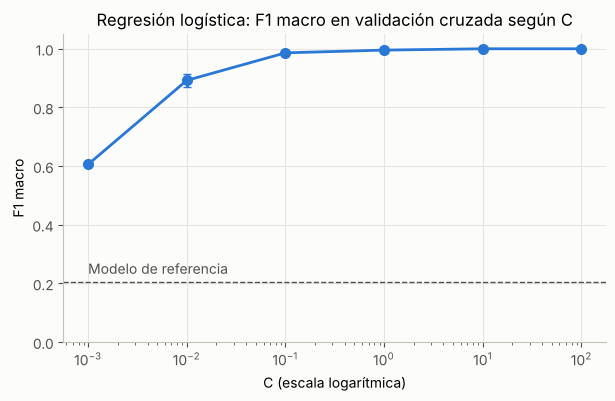

In [11]:
lr_rows = cv_results[cv_results["modelo"] == "logistic_regression"]
baseline_f1 = cv_results.loc[cv_results["modelo"] == "baseline_most_frequent", "f1_macro_mean"].iloc[0]

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    lr_rows["C"], lr_rows["f1_macro_mean"], yerr=lr_rows["f1_macro_std"],
    color="#2a78d6", linewidth=2, marker="o", markersize=7, capsize=3,
)
ax.axhline(baseline_f1, color="#52514e", linestyle="--", linewidth=1)
ax.annotate("Modelo de referencia", (lr_rows["C"].min(), baseline_f1),
            xytext=(0, 6), textcoords="offset points", color="#52514e")
ax.set_xscale("log")
ax.set_ylim(0, 1.05)
ax.set_xlabel("C (escala logarítmica)")
ax.set_ylabel("F1 macro")
ax.set_title("Regresión logística: F1 macro en validación cruzada según C")
fig.savefig(FIGURES_DIR / "model_cv_c.png")
plt.show()

#### Modelo final

In [12]:
final_model = search.best_estimator_
baseline.fit(X_train, y_train)

train_acc = (final_model.predict(X_train) == y_train).mean()
print(f"Exactitud en entrenamiento: {train_acc:.3f}")

Exactitud en entrenamiento: 1.000


#### Coeficientes del modelo

In [13]:
classifier = final_model.named_steps["classifier"]
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = pd.DataFrame(classifier.coef_.T, index=feature_names, columns=classifier.classes_)
coefficients.loc["intercept"] = classifier.intercept_
coefficients.index.name = "variable"
coefficients.round(3)

,Adelie,Chinstrap,Gentoo
variable,,,
culmen_length_mm,-3.825,3.159,0.667
culmen_depth_mm,1.711,0.205,-1.915
flipper_length_mm,-1.037,-0.349,1.387
body_mass_g,-0.006,-1.405,1.412
island_Biscoe,0.300,-1.175,0.875
island_Dream,-0.933,1.709,-0.776
island_Torgersen,0.904,-0.770,-0.134
sex_FEMALE,-1.017,0.879,0.138
sex_MALE,1.263,-1.082,-0.181


#### Guardado de resultados

In [14]:
cv_results.to_csv(PROCESSED_DIR / "cv_results.csv", index=False)
coefficients.to_csv(PROCESSED_DIR / "lr_coefficients.csv")
joblib.dump(final_model, MODELS_DIR / "logistic_regression.joblib")
joblib.dump(baseline, MODELS_DIR / "baseline.joblib")

for path in [
    PROCESSED_DIR / "cv_results.csv",
    PROCESSED_DIR / "lr_coefficients.csv",
    MODELS_DIR / "logistic_regression.joblib",
    MODELS_DIR / "baseline.joblib",
    FIGURES_DIR / "model_cv_c.png",
]:
    print(f"Guardado: {path}")

Guardado: ../data/processed/cv_results.csv
Guardado: ../data/processed/lr_coefficients.csv
Guardado: ../models/logistic_regression.joblib
Guardado: ../models/baseline.joblib
Guardado: ../figures/model_cv_c.png
